In [131]:
import warnings

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier


from sklearn.metrics import accuracy_score, precision_score, f1_score, recall_score, confusion_matrix, classification_report


warnings.filterwarnings('ignore')

In [118]:
df = pd.read_csv("diabetes.csv")

df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [119]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [120]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [121]:
columns_to_check = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

def zero_value_report(df, columns):
    results = []
    
    for col in columns:
        zero_count = (df[col] == 0).sum() # 0 olarak girilen null degerler.
        zero_percentage = 100 * (zero_count/len(df)) # 0larin yuzdeligi.
        
        results.append({
            "Column" : col,
            "zero_count" : zero_count,
            "zero_percentage" : round(zero_percentage, 2)
        })
        
    return pd.DataFrame(results) 

zero_value_report(df, columns_to_check)    

,Column,zero_count,zero_percentage
0,Pregnancies,111,14.45
1,Glucose,5,0.65
2,BloodPressure,35,4.56
3,SkinThickness,227,29.56
4,Insulin,374,48.70
5,BMI,11,1.43


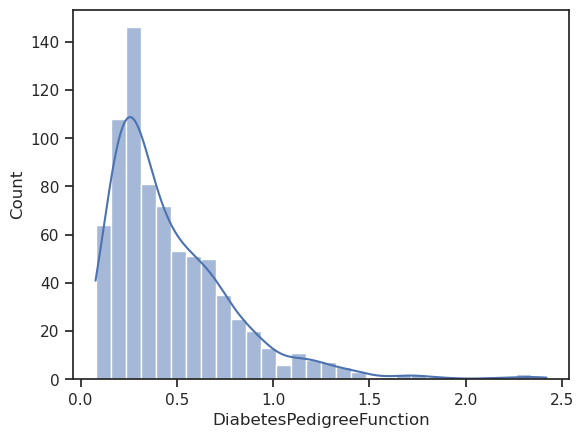

In [122]:
sns.set_theme(style=("ticks"))
sns.histplot(df["DiabetesPedigreeFunction"], bins=30, kde=True)
plt.show()

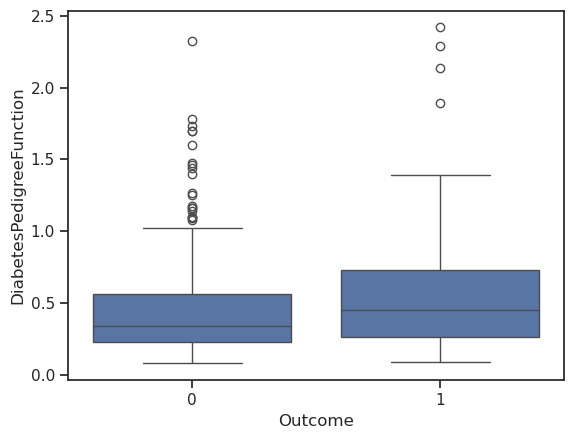

In [123]:
sns.boxplot(x=df["Outcome"], y=df["DiabetesPedigreeFunction"])
plt.show()

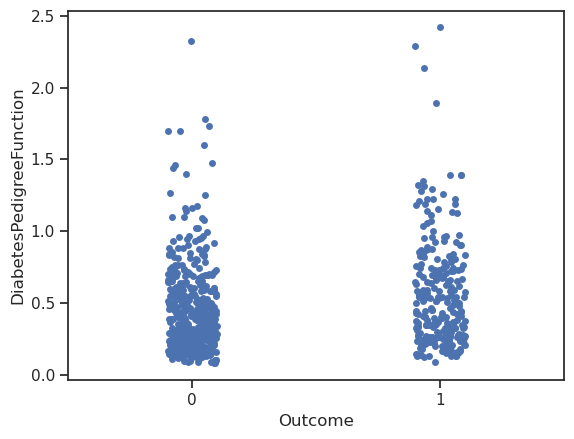

In [124]:
sns.set_theme(style=("ticks"))
sns.stripplot(
    x=df["Outcome"],
    y=df["DiabetesPedigreeFunction"],
    data=df,
    jitter=True
)

plt.show()

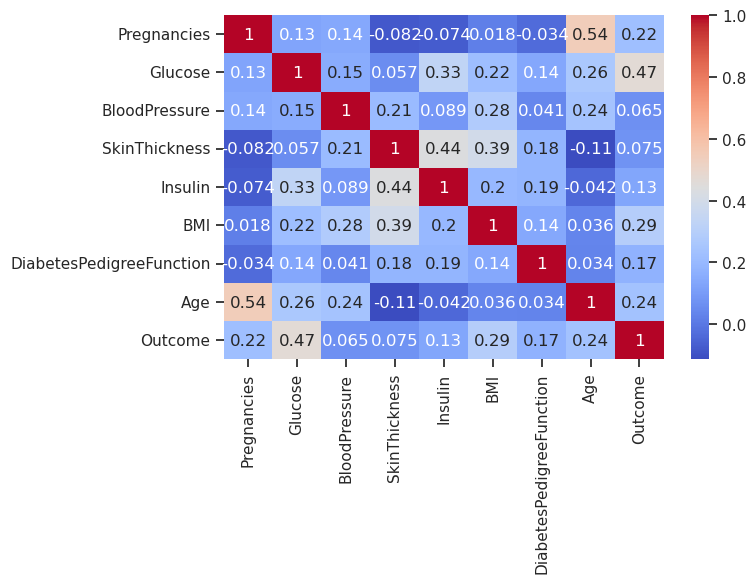

In [125]:
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.tight_layout()
plt.show()

In [126]:
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=15)

In [127]:
columns_to_fill = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

def zero_value_impute(X_train, X_test, columns):
    medians = {}

    for col in columns_to_fill:
        median_value = X_train[X_train[col] != 0][col].median() # X_train in medianlarini hesaplayip 0 lari medianla degistirdik.
        medians[col] = median_value
        X_train[col] = X_train[col].replace(0, median_value)

    for col in columns_to_fill:                      # X_train in medianlari ile X_testteki 0 lari degistirdik
        X_test[col] = X_test[col].replace(0, medians[col])

    return X_train, X_test, medians

zero_value_impute(X_train, X_test, columns_to_fill)   

(     Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
 304            3      150             76             29    129.5  21.0   
 297            4      126             84             29    215.0  30.7   
 522            6      114             72             29    129.5  32.3   
 618            9      112             82             24    129.5  28.2   
 501            3       84             72             32    129.5  37.2   
 ..           ...      ...            ...            ...      ...   ...   
 156            2       99             52             15     94.0  24.6   
 384            1      125             70             24    110.0  24.3   
 645            2      157             74             35    440.0  39.4   
 757            4      123             72             29    129.5  36.3   
 456            1      135             54             29    129.5  26.7   
 
      DiabetesPedigreeFunction  Age  
 304                     0.207   37  
 297                  

In [128]:
X_train.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
count,614.000000,614.000000,614.000000,614.000000,614.000000,614.000000,614.000000,614.000000
mean,4.467427,121.560261,72.612378,29.040717,142.477199,32.448208,0.469948,33.285016
std,3.001046,29.974412,12.165642,8.312217,80.879330,6.862948,0.328516,11.678337
min,1.000000,44.000000,24.000000,7.000000,14.000000,18.200000,0.084000,21.000000
25%,2.000000,100.000000,64.000000,25.000000,125.000000,27.600000,0.238250,24.000000
50%,4.000000,117.000000,72.000000,29.000000,129.500000,32.300000,0.370500,29.000000
75%,6.000000,139.750000,80.000000,32.000000,130.000000,36.500000,0.630750,40.000000
max,17.000000,199.000000,122.000000,63.000000,680.000000,67.100000,2.420000,81.000000


In [132]:
models = {
    "logistic" : LogisticRegression(),
    "svc" : SVC(),
    "gnb" : GaussianNB(),
    "knn" : KNeighborsClassifier(),
    "tree" : DecisionTreeClassifier(),
    "rf" : RandomForestClassifier()
}

def model_score(models, X_train, X_test, y_train):
    result = []
    
    for name, model in models.items():
        pipe = Pipeline([
            ("scaler", StandardScaler()),
            ("model", model)
        ])

        cv_score = cross_val_score(pipe, X_train, y_train, scoring="accuracy", cv=5)

        pipe.fit(X_train, y_train)
        y_pred = pipe.predict(X_test)

        acc = accuracy_score(y_test, y_pred)
        prec = precision_score(y_test, y_pred)
        rec = recall_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred)

        result.append ({
            "Model Name" : name,
            "Test Accuracy" : acc,
            "CV Accuracy" : cv_score.mean(),
            "Precision" : prec,
            "Recal" : rec,
            "F1" : f1
            
        })

    df_result = pd.DataFrame(result)

    df_result = df_result.sort_values(by="Test Accuracy", ascending=False)

    return df_result

model_score(models, X_train, X_test, y_train)       

,Model Name,Test Accuracy,CV Accuracy,Precision,Recal,F1
0,logistic,0.746753,0.773597,0.577778,0.565217,0.571429
1,svc,0.733766,0.762215,0.555556,0.543478,0.549451
2,gnb,0.720779,0.757310,0.530612,0.565217,0.547368
5,rf,0.714286,0.776849,0.520000,0.565217,0.541667
3,knn,0.675325,0.750820,0.460000,0.500000,0.479167
4,tree,0.668831,0.713381,0.457627,0.586957,0.514286


In [138]:
pipe = Pipeline([
            ("scaler", StandardScaler()),
            ("model", KNeighborsClassifier())
        ])

params = [
    {
        "model" : [KNeighborsClassifier()],
        "model__n_neighbors" : [5, 10, 15, 20],
        "model__algorithm" : ['auto', 'ball_tree', 'kd_tree', 'brute'],
        "model__weights" : ['uniform', 'distance']
    },
    {
        "model" : [LogisticRegression()],
        "model__penalty" : ['l1', 'l2', 'elasticnet'],
        "model__C" : [0.01, 0.1, 1, 10, 100, 1000],
        "model__solver" : ['newton-cg', 'liblinear', 'lbfgs', 'saga']
    },
    {
        "model" : [SVC()],
        "model__C" : [0.1, 1, 10, 100, 1000],
        "model__kernel" : ['rbf', 'sigmoid'],
        "model__gamma" : ['scale', 'auto']
    }
]

grid = GridSearchCV(
    pipe,
    param_grid=params,
    cv=5,
    verbose=1,
    n_jobs=-1
)

grid.fit(X_train, y_train)
y_pred1 = grid.predict(X_test)

def score_table(search, y_test, y_pred1):
    table = []

    acc = accuracy_score(y_test, y_pred1)
    prec = precision_score(y_test, y_pred1)
    rec = recall_score(y_test, y_pred1)
    f1 = f1_score(y_test, y_pred1)
        
    table.append ({
        "Model Name" : grid.best_params_['model'],
        "Best Score" : grid.best_score_,
        "Test Accuracy" : acc,
        "Precision" : prec,
        "Recal" : rec,
        "F1" : f1
    })
    
    print("\n", "Classification Report: \n", classification_report(y_test, y_pred1))
    print("-"*60)
    print("Confusion Matrix: \n", confusion_matrix(y_test, y_pred1), "\n")
    
    return pd.DataFrame(table)

score_table(grid, y_test, y_pred1)

Fitting 5 folds for each of 124 candidates, totalling 620 fits

 Classification Report: 
               precision    recall  f1-score   support

           0       0.82      0.82      0.82       108
           1       0.58      0.57      0.57        46

    accuracy                           0.75       154
   macro avg       0.70      0.69      0.70       154
weighted avg       0.75      0.75      0.75       154

------------------------------------------------------------
Confusion Matrix: 
 [[89 19]
 [20 26]] 



,Model Name,Best Score,Test Accuracy,Precision,Recal,F1
0,LogisticRegression(),0.778502,0.746753,0.577778,0.565217,0.571429
